# Assessment 2: Pre-Rental Clothing Fit Risk Prediction

**Option 2: Machine Learning System Implementation**

**Student Name:** Xuefei Zhao

## 1. Problem Definition

Selecting an unsuitable clothing size is a practical challenge in online clothing rental because customers cannot physically try on an item before making a rental decision. This project investigates whether a machine learning system can predict whether a selected item is likely to be `small`, `fit` or `large` using information available before the rental is completed.

The intended application is a pre-rental warning system. If an item is predicted to be too small or too large, the system could ask the customer to review the selected size before confirming the rental. The system is designed to identify potentially unsuitable selections while avoiding excessive false warnings for items that would fit correctly.

### Research Question

Can a machine learning system predict whether a selected rental item will be small, suitable or large using customer measurements, garment information and rental context, and can class-imbalance treatment improve the identification of potentially unsuitable rentals?

### Data Source

The project uses the publicly available RentTheRunway Clothing Fit dataset released by the McAuley Lab at the University of California San Diego. The dataset contains customer characteristics, clothing information, rental context and reported fit outcomes.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
data_url = (
    "https://mcauleylab.ucsd.edu/public_datasets/"
    "data/renttherunway/renttherunway_final_data.json.gz"
)

df = pd.read_json(
    data_url,
    lines=True,
    compression="gzip"
)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (192544, 15)


In [3]:
df.head()

,fit,user_id,bust size,item_id,weight,rating,rented for,review_text,body type,review_summary,category,height,size,age,review_date
0,fit,420272,34d,2260466,137lbs,10.0,vacation,An adorable romper! Belt and zipper were a lit...,hourglass,So many compliments!,romper,"5' 8""",14,28.0,"April 20, 2016"
1,fit,273551,34b,153475,132lbs,10.0,other,I rented this dress for a photo shoot. The the...,straight & narrow,I felt so glamourous!!!,gown,"5' 6""",12,36.0,"June 18, 2013"
2,fit,360448,NaN,1063761,NaN,10.0,party,This hugged in all the right places! It was a ...,NaN,It was a great time to celebrate the (almost) ...,sheath,"5' 4""",4,116.0,"December 14, 2015"
3,fit,909926,34c,126335,135lbs,8.0,formal affair,I rented this for my company's black tie award...,pear,Dress arrived on time and in perfect condition.,dress,"5' 5""",8,34.0,"February 12, 2014"
4,fit,151944,34b,616682,145lbs,10.0,wedding,I have always been petite in my upper body and...,athletic,Was in love with this dress !!!,gown,"5' 9""",12,27.0,"September 26, 2016"


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 192544 entries, 0 to 192543
Data columns (total 15 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   fit             192544 non-null  object 
 1   user_id         192544 non-null  int64  
 2   bust size       174133 non-null  object 
 3   item_id         192544 non-null  int64  
 4   weight          162562 non-null  object 
 5   rating          192462 non-null  float64
 6   rented for      192534 non-null  object 
 7   review_text     192544 non-null  object 
 8   body type       177907 non-null  object 
 9   review_summary  192544 non-null  object 
 10  category        192544 non-null  object 
 11  height          191867 non-null  object 
 12  size            192544 non-null  int64  
 13  age             191584 non-null  float64
 14  review_date     192544 non-null  object 
dtypes: float64(2), int64(3), object(10)
memory usage: 22.0+ MB


In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

Number of rows: 192544
Number of columns: 15

Column names:
['fit', 'user_id', 'bust size', 'item_id', 'weight', 'rating', 'rented for', 'review_text', 'body type', 'review_summary', 'category', 'height', 'size', 'age', 'review_date']


In [6]:
fit_counts = df["fit"].value_counts()

print("Target variable distribution:")
print(fit_counts)

print("\nTarget variable percentages:")
print((df["fit"].value_counts(normalize=True) * 100).round(2))

Target variable distribution:
fit
fit      142058
small     25779
large     24707
Name: count, dtype: int64

Target variable percentages:
fit
fit      73.78
small    13.39
large    12.83
Name: proportion, dtype: float64


In [7]:
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_values = missing_values.sort_values(
    by="Missing Values",
    ascending=False
)

missing_values

,Missing Values,Missing Percentage
weight,29982,15.57
bust size,18411,9.56
body type,14637,7.60
age,960,0.50
height,677,0.35
rating,82,0.04
rented for,10,0.01
item_id,0,0.00
user_id,0,0.00
fit,0,0.00


## 2. Data Quality Assessment

The dataset is examined for duplicate records, missing values, unusual numerical values and inconsistent categories before model development.

In [8]:
print("Number of duplicated rows:", df.duplicated().sum())

df[["age", "rating", "size"]].describe()

Number of duplicated rows: 189


,age,rating,size
count,191584.000000,192462.000000,192544.000000
mean,33.871017,9.092371,12.245175
std,8.058083,1.430044,8.494877
min,0.000000,2.000000,0.000000
25%,29.000000,8.000000,8.000000
50%,32.000000,10.000000,12.000000
75%,37.000000,10.000000,16.000000
max,117.000000,10.000000,58.000000


In [9]:
print("Age range:", df["age"].min(), "to", df["age"].max())
print("Rating values:", sorted(df["rating"].dropna().unique()))
print("Size range:", df["size"].min(), "to", df["size"].max())

print("\nRented-for categories:")
print(df["rented for"].value_counts(dropna=False))

print("\nBody-type categories:")
print(df["body type"].value_counts(dropna=False))

Age range: 0.0 to 117.0
Rating values: [np.float64(2.0), np.float64(4.0), np.float64(6.0), np.float64(8.0), np.float64(10.0)]
Size range: 0 to 58

Rented-for categories:
rented for
wedding            57784
formal affair      40408
party              35626
everyday           16822
other              15388
work               15042
date                7388
vacation            4075
NaN                   10
party: cocktail        1
Name: count, dtype: int64

Body-type categories:
body type
hourglass            55349
athletic             43667
pear                 22135
petite               22131
full bust            15006
straight & narrow    14742
NaN                  14637
apple                 4877
Name: count, dtype: int64


### Feature Selection

Post-rental variables, including rating and review content, were excluded because they would not be available when a customer selects a clothing item. Identifier variables were also excluded from the initial model to reduce memorisation and improve generalisability.

In [10]:
model_df = df[
    [
        "fit",
        "bust size",
        "weight",
        "rented for",
        "body type",
        "category",
        "height",
        "size",
        "age"
    ]
].copy()

model_df = model_df.rename(
    columns={
        "bust size": "bust_size",
        "rented for": "rented_for",
        "body type": "body_type"
    }
)

print("Selected dataset shape:", model_df.shape)
model_df.head()

Selected dataset shape: (192544, 9)


,fit,bust_size,weight,rented_for,body_type,category,height,size,age
0,fit,34d,137lbs,vacation,hourglass,romper,"5' 8""",14,28.0
1,fit,34b,132lbs,other,straight & narrow,gown,"5' 6""",12,36.0
2,fit,NaN,NaN,party,NaN,sheath,"5' 4""",4,116.0
3,fit,34c,135lbs,formal affair,pear,dress,"5' 5""",8,34.0
4,fit,34b,145lbs,wedding,athletic,gown,"5' 9""",12,27.0


In [11]:
# Convert weight from text such as "137lbs" to numeric pounds
model_df["weight_lbs"] = pd.to_numeric(
    model_df["weight"].str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

# Convert height from feet and inches to total inches
height_parts = model_df["height"].str.extract(
    r"(\d+)'\s*(\d+)"
)

model_df["height_inches"] = (
    pd.to_numeric(height_parts[0], errors="coerce") * 12
    + pd.to_numeric(height_parts[1], errors="coerce")
)

model_df[
    ["weight", "weight_lbs", "height", "height_inches"]
].head()

,weight,weight_lbs,height,height_inches
0,137lbs,137.0,"5' 8""",68.0
1,132lbs,132.0,"5' 6""",66.0
2,NaN,NaN,"5' 4""",64.0
3,135lbs,135.0,"5' 5""",65.0
4,145lbs,145.0,"5' 9""",69.0


## 3. Data Preparation

Exact duplicate records were removed. Implausible age values were treated as missing values rather than deleting the entire observations. Missing numerical and categorical values will later be imputed using the training data.

In [12]:
# Remove only exact duplicates from the original dataset
df_clean = df.drop_duplicates().copy()

print("Original rows:", df.shape[0])
print("Rows after removing duplicates:", df_clean.shape[0])
print("Rows removed:", df.shape[0] - df_clean.shape[0])

Original rows: 192544
Rows after removing duplicates: 192355
Rows removed: 189


In [13]:
model_df = df_clean[
    [
        "fit",
        "bust size",
        "weight",
        "rented for",
        "body type",
        "category",
        "height",
        "size",
        "age"
    ]
].copy()

model_df = model_df.rename(
    columns={
        "bust size": "bust_size",
        "rented for": "rented_for",
        "body type": "body_type"
    }
)

In [14]:
# Combine the single inconsistent category with "party"
model_df["rented_for"] = model_df["rented_for"].replace(
    "party: cocktail",
    "party"
)

# Convert weight to numeric pounds
model_df["weight_lbs"] = pd.to_numeric(
    model_df["weight"].str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

# Convert height to total inches
height_parts = model_df["height"].str.extract(
    r"(\d+)'\s*(\d+)"
)

model_df["height_inches"] = (
    pd.to_numeric(height_parts[0], errors="coerce") * 12
    + pd.to_numeric(height_parts[1], errors="coerce")
)

# Identify implausible ages
invalid_age = (
    model_df["age"].notna()
    & ~model_df["age"].between(16, 80)
)

print("Implausible age values:", invalid_age.sum())

# Treat implausible ages as missing
model_df.loc[invalid_age, "age"] = np.nan

# Remove the original text versions after conversion
model_df = model_df.drop(
    columns=["weight", "height"]
)

print("Prepared dataset shape:", model_df.shape)
model_df.head()

Implausible age values: 184
Prepared dataset shape: (192355, 9)


,fit,bust_size,rented_for,body_type,category,size,age,weight_lbs,height_inches
0,fit,34d,vacation,hourglass,romper,14,28.0,137.0,68.0
1,fit,34b,other,straight & narrow,gown,12,36.0,132.0,66.0
2,fit,NaN,party,NaN,sheath,4,NaN,NaN,64.0
3,fit,34c,formal affair,pear,dress,8,34.0,135.0,65.0
4,fit,34b,wedding,athletic,gown,12,27.0,145.0,69.0


In [15]:
cleaning_summary = pd.DataFrame({
    "Data Type": model_df.dtypes,
    "Missing Values": model_df.isnull().sum(),
    "Missing Percentage": (
        model_df.isnull().mean() * 100
    ).round(2)
})

cleaning_summary

,Data Type,Missing Values,Missing Percentage
fit,object,0,0.00
bust_size,object,18392,9.56
rented_for,object,10,0.01
body_type,object,14625,7.60
category,object,0,0.00
size,int64,0,0.00
age,float64,1144,0.59
weight_lbs,float64,29955,15.57
height_inches,float64,675,0.35


In [16]:
model_df[
    ["size", "age", "weight_lbs", "height_inches"]
].describe()

,size,age,weight_lbs,height_inches
count,192355.000000,191211.000000,162400.000000,191680.000000
mean,12.245801,33.846630,137.392445,65.310424
std,8.496299,7.863016,21.902426,2.663561
min,0.000000,16.000000,50.000000,54.000000
25%,8.000000,29.000000,123.000000,63.000000
50%,12.000000,32.000000,135.000000,65.000000
75%,16.000000,37.000000,148.000000,67.000000
max,58.000000,78.000000,300.000000,78.000000


### Target Class Distribution

The target classes are imbalanced, with correctly fitting items representing most observations. Therefore, accuracy alone may provide a misleading evaluation of model performance.

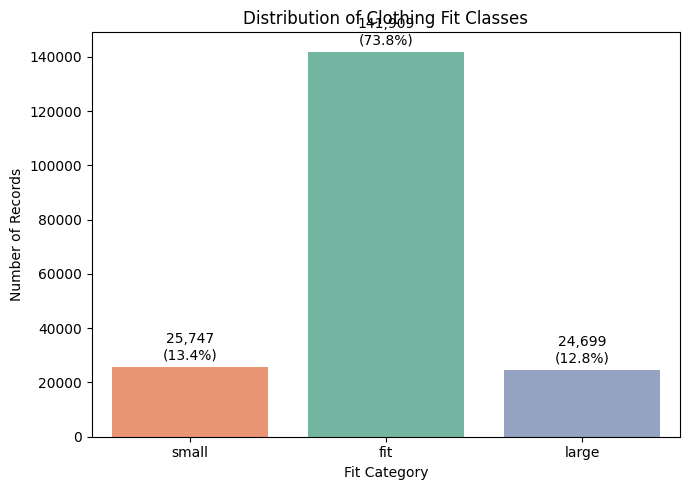

In [17]:
target_order = ["small", "fit", "large"]

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=model_df,
    x="fit",
    order=target_order,
    hue="fit",
    palette="Set2",
    legend=False
)

total = len(model_df)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[
            f"{bar.get_height():,.0f}\n"
            f"({bar.get_height() / total * 100:.1f}%)"
            for bar in container
        ],
        padding=3
    )

plt.title("Distribution of Clothing Fit Classes")
plt.xlabel("Fit Category")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

## 4. Initial Machine Learning System Design

### Initial Training Interface

The initial system uses eight general customer and rental-related features: selected clothing size, customer age, weight, height, bust size, body type, clothing category and rental purpose. The corresponding target is one of three observed fit labels: `small`, `fit` or `large`.

This initial feature set excludes customer and product identifiers. It is intended to test whether general customer measurements, garment attributes and rental context are sufficient for predicting clothing fit.

### Initial Deployment Interface

During deployment, the initial system accepts the same eight inputs for a new rental decision and returns one predicted fit category: `small`, `fit` or `large`. A prediction of `small` or `large` could be used to ask the customer to review the selected size before confirming the rental.

The initial system is first compared with a majority-class baseline. Its validation results are then used to identify limitations and guide subsequent model refinement.

### Training, Validation and Test Split

The prepared dataset was divided into 70% training data, 15% validation data and 15% test data using stratified sampling. The validation set is used for model selection and refinement, while the test set is reserved for the final evaluation.

In [18]:
from sklearn.model_selection import train_test_split

X = model_df.drop(columns="fit")
y = model_df["fit"]

# First split: 70% training and 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# Second split: divide temporary data equally into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nTraining class percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nValidation class percentages:")
print((y_val.value_counts(normalize=True) * 100).round(2))

print("\nTest class percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training set: (134648, 8)
Validation set: (28853, 8)
Test set: (28854, 8)

Training class percentages:
fit
fit      73.77
small    13.39
large    12.84
Name: proportion, dtype: float64

Validation class percentages:
fit
fit      73.77
small    13.39
large    12.84
Name: proportion, dtype: float64

Test class percentages:
fit
fit      73.77
small    13.38
large    12.84
Name: proportion, dtype: float64


### Preprocessing Pipeline

Numerical variables are imputed using the training-set median and standardised. Missing categorical values are represented as `Unknown`, after which categorical variables are converted using one-hot encoding. The preprocessing steps are fitted only on the training data through the model pipeline to prevent data leakage.

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = [
    "size",
    "age",
    "weight_lbs",
    "height_inches"
]

categorical_features = [
    "bust_size",
    "rented_for",
    "body_type",
    "category"
]

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Unknown"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numeric_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## 5. Initial Model Evaluation

Because the target classes are imbalanced, accuracy is reported together with balanced accuracy, macro F1-score, class-specific precision and recall, and a confusion matrix. Macro F1 gives equal importance to the three fit categories.

In [20]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

class_order = ["small", "fit", "large"]

def evaluate_model(model_name, model, X_data, y_true):
    y_pred = model.predict(X_data)

    accuracy = accuracy_score(y_true, y_pred)
    balanced_accuracy = balanced_accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro"
    )

    print(f"{model_name}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Balanced accuracy: {balanced_accuracy:.4f}")
    print(f"Macro F1-score: {macro_f1:.4f}")

    print("\nClassification report:")
    report = classification_report(
        y_true,
        y_pred,
        labels=class_order,
        output_dict=True,
        zero_division=0
    )

    display(
        pd.DataFrame(report).transpose().round(3)
    )

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=class_order
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt=",d",
        cmap="Blues",
        xticklabels=class_order,
        yticklabels=class_order
    )

    plt.title(f"{model_name}: Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.show()

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced_accuracy,
        "Macro F1": macro_f1
    }, y_pred

Majority-Class Baseline
Accuracy: 0.7377
Balanced accuracy: 0.3333
Macro F1-score: 0.2830

Classification report:


,precision,recall,f1-score,support
small,0.000,0.000,0.000,3862.000
fit,0.738,1.000,0.849,21286.000
large,0.000,0.000,0.000,3705.000
accuracy,0.738,0.738,0.738,0.738
macro avg,0.246,0.333,0.283,28853.000
weighted avg,0.544,0.738,0.626,28853.000


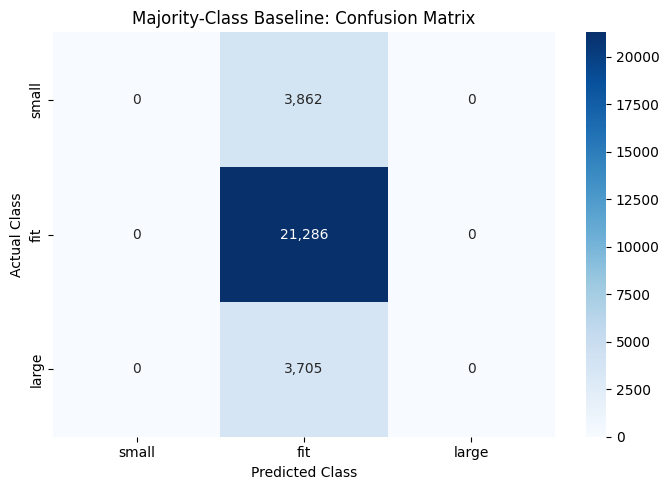

In [21]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(X_train, y_train)

dummy_metrics, dummy_predictions = evaluate_model(
    "Majority-Class Baseline",
    dummy_model,
    X_val,
    y_val
)

Training time: 10.94 seconds
Standard Logistic Regression
Accuracy: 0.7362
Balanced accuracy: 0.3348
Macro F1-score: 0.2879

Classification report:


,precision,recall,f1-score,support
small,0.194,0.005,0.009,3862.000
fit,0.738,0.997,0.848,21286.000
large,0.429,0.003,0.006,3705.000
accuracy,0.736,0.736,0.736,0.736
macro avg,0.453,0.335,0.288,28853.000
weighted avg,0.626,0.736,0.628,28853.000


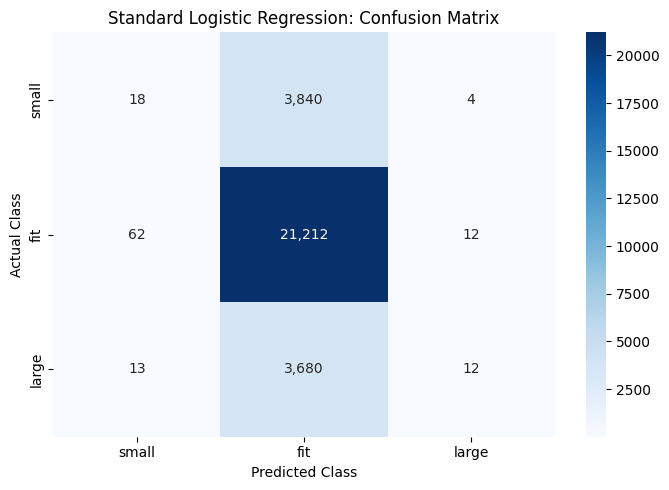

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
import time

standard_lr = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=500,
                solver="lbfgs",
                random_state=RANDOM_STATE
            )
        )
    ]
)

start_time = time.time()

standard_lr.fit(
    X_train,
    y_train
)

standard_lr_time = time.time() - start_time

print(
    f"Training time: {standard_lr_time:.2f} seconds"
)

standard_lr_metrics, standard_lr_predictions = evaluate_model(
    "Standard Logistic Regression",
    standard_lr,
    X_val,
    y_val
)

Training time: 15.45 seconds
Class-Weighted Logistic Regression
Accuracy: 0.3590
Balanced accuracy: 0.4689
Macro F1-score: 0.3372

Classification report:


,precision,recall,f1-score,support
small,0.206,0.564,0.302,3862.000
fit,0.803,0.288,0.424,21286.000
large,0.193,0.555,0.286,3705.000
accuracy,0.359,0.359,0.359,0.359
macro avg,0.401,0.469,0.337,28853.000
weighted avg,0.645,0.359,0.390,28853.000


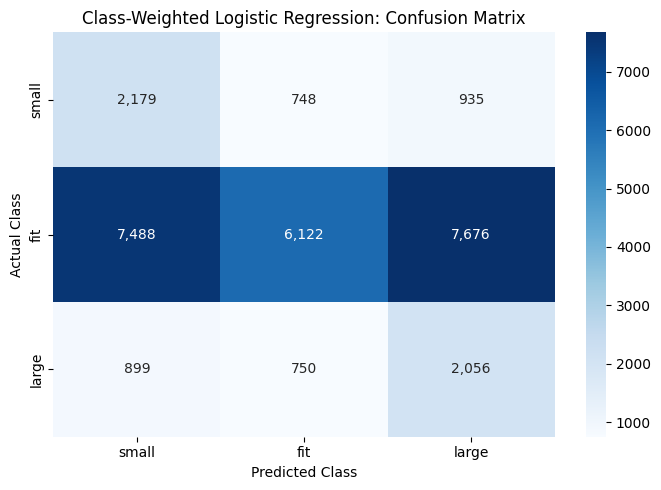

In [23]:
balanced_lr = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=500,
                solver="lbfgs",
                class_weight="balanced",
                random_state=RANDOM_STATE
            )
        )
    ]
)

start_time = time.time()

balanced_lr.fit(
    X_train,
    y_train
)

balanced_lr_time = time.time() - start_time

print(
    f"Training time: {balanced_lr_time:.2f} seconds"
)

balanced_lr_metrics, balanced_lr_predictions = evaluate_model(
    "Class-Weighted Logistic Regression",
    balanced_lr,
    X_val,
    y_val
)

In [24]:
current_results = pd.DataFrame(
    [
        dummy_metrics,
        standard_lr_metrics,
        balanced_lr_metrics
    ]
)

current_results = current_results.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

current_results.round(4)

,Model,Accuracy,Balanced Accuracy,Macro F1
0,Class-Weighted Logistic Regression,0.3590,0.4689,0.3372
1,Standard Logistic Regression,0.7362,0.3348,0.2879
2,Majority-Class Baseline,0.7377,0.3333,0.2830


## 6. Model Refinement with Product Identity

### Refinement Rationale

The initial models only used general customer and garment attributes. However, validation results showed that the standard logistic regression performed similarly to the majority-class baseline. Although class weighting improved balanced accuracy and macro F1-score, its overall predictive performance remained limited.

Garments with the same category and labelled size may have different fit characteristics. The refined model therefore adds `item_id` as a categorical input to capture product-specific fit patterns.

### Refined Training Interface

The refined model uses the original eight features together with `item_id`, resulting in nine input features. The target remains one of three fit labels: `small`, `fit` or `large`.

### Refined Deployment Interface

The refined system is primarily intended for garments already represented in the platform's historical rental data. For a known item, it uses customer information, rental context and product identity to produce one predicted fit category.

For completely new items that have not appeared in the training data, the product-specific component provides no learned information. Predictions for these items depend mainly on the remaining general features.

In [25]:
refined_model_df = model_df.copy()

# Add product identity using the matching original row index
refined_model_df["item_id"] = (
    df_clean.loc[
        refined_model_df.index,
        "item_id"
    ].astype(str)
)

print(
    "Refined dataset shape:",
    refined_model_df.shape
)

print(
    "Number of unique items:",
    refined_model_df["item_id"].nunique()
)

refined_model_df.head()

Refined dataset shape: (192355, 10)
Number of unique items: 5850


,fit,bust_size,rented_for,body_type,category,size,age,weight_lbs,height_inches,item_id
0,fit,34d,vacation,hourglass,romper,14,28.0,137.0,68.0,2260466
1,fit,34b,other,straight & narrow,gown,12,36.0,132.0,66.0,153475
2,fit,NaN,party,NaN,sheath,4,NaN,NaN,64.0,1063761
3,fit,34c,formal affair,pear,dress,8,34.0,135.0,65.0,126335
4,fit,34b,wedding,athletic,gown,12,27.0,145.0,69.0,616682


In [26]:
X_refined = refined_model_df.drop(
    columns="fit"
)

y_refined = refined_model_df["fit"]

X_train_refined, X_temp_refined, y_train_refined, y_temp_refined = (
    train_test_split(
        X_refined,
        y_refined,
        test_size=0.30,
        random_state=RANDOM_STATE,
        stratify=y_refined
    )
)

X_val_refined, X_test_refined, y_val_refined, y_test_refined = (
    train_test_split(
        X_temp_refined,
        y_temp_refined,
        test_size=0.50,
        random_state=RANDOM_STATE,
        stratify=y_temp_refined
    )
)

print(
    "Refined training set:",
    X_train_refined.shape
)

print(
    "Refined validation set:",
    X_val_refined.shape
)

print(
    "Refined test set:",
    X_test_refined.shape
)

Refined training set: (134648, 9)
Refined validation set: (28853, 9)
Refined test set: (28854, 9)


In [27]:
refined_numeric_features = [
    "size",
    "age",
    "weight_lbs",
    "height_inches"
]

refined_categorical_features = [
    "bust_size",
    "rented_for",
    "body_type",
    "category",
    "item_id"
]

refined_numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

refined_categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Unknown"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

refined_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            refined_numeric_transformer,
            refined_numeric_features
        ),
        (
            "categorical",
            refined_categorical_transformer,
            refined_categorical_features
        )
    ]
)

print(
    "Refined preprocessing pipeline created successfully."
)

Refined preprocessing pipeline created successfully.


Training time: 43.37 seconds
Refined Class-Weighted Logistic Regression
Accuracy: 0.5257
Balanced accuracy: 0.6061
Macro F1-score: 0.4795

Classification report:


,precision,recall,f1-score,support
small,0.300,0.666,0.414,3862.000
fit,0.842,0.474,0.606,21286.000
large,0.303,0.678,0.418,3705.000
accuracy,0.526,0.526,0.526,0.526
macro avg,0.482,0.606,0.480,28853.000
weighted avg,0.700,0.526,0.556,28853.000


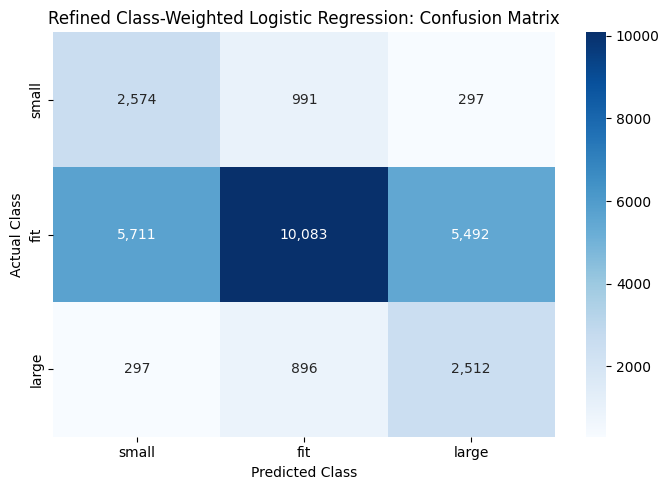

In [28]:
refined_balanced_lr = Pipeline(
    steps=[
        (
            "preprocessor",
            refined_preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=500,
                solver="lbfgs",
                class_weight="balanced",
                random_state=RANDOM_STATE
            )
        )
    ]
)

start_time = time.time()

refined_balanced_lr.fit(
    X_train_refined,
    y_train_refined
)

refined_lr_time = time.time() - start_time

print(
    f"Training time: {refined_lr_time:.2f} seconds"
)

refined_lr_metrics, refined_lr_predictions = evaluate_model(
    "Refined Class-Weighted Logistic Regression",
    refined_balanced_lr,
    X_val_refined,
    y_val_refined
)

In [29]:
refined_comparison = pd.DataFrame(
    [
        dummy_metrics,
        standard_lr_metrics,
        balanced_lr_metrics,
        refined_lr_metrics
    ]
)

refined_comparison = refined_comparison.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

refined_comparison.round(4)

,Model,Accuracy,Balanced Accuracy,Macro F1
0,Refined Class-Weighted Logistic Regression,0.5257,0.6061,0.4795
1,Class-Weighted Logistic Regression,0.3590,0.4689,0.3372
2,Standard Logistic Regression,0.7362,0.3348,0.2879
3,Majority-Class Baseline,0.7377,0.3333,0.2830


### Business-Oriented Evaluation

For the intended warning system, a prediction of `small` or `large` is treated as a misfit alert. Misfit recall measures how many actually unsuitable rentals are identified, while the false alert rate measures how often correctly fitting rentals receive an unnecessary warning.

In [30]:
from sklearn.metrics import (
    precision_score,
    recall_score
)

def calculate_business_metrics(
    model_name,
    y_true,
    y_pred
):
    actual_misfit = (
        np.asarray(y_true) != "fit"
    )

    predicted_misfit = (
        np.asarray(y_pred) != "fit"
    )

    misfit_recall = recall_score(
        actual_misfit,
        predicted_misfit,
        zero_division=0
    )

    misfit_precision = precision_score(
        actual_misfit,
        predicted_misfit,
        zero_division=0
    )

    actual_fit = ~actual_misfit

    false_alert_rate = (
        (
            actual_fit
            & predicted_misfit
        ).sum()
        / actual_fit.sum()
    )

    return {
        "Model": model_name,
        "Misfit Recall": misfit_recall,
        "Misfit Precision": misfit_precision,
        "False Alert Rate": false_alert_rate
    }

In [31]:
business_results = pd.DataFrame(
    [
        calculate_business_metrics(
            "Majority-Class Baseline",
            y_val,
            dummy_predictions
        ),
        calculate_business_metrics(
            "Standard Logistic Regression",
            y_val,
            standard_lr_predictions
        ),
        calculate_business_metrics(
            "Class-Weighted Logistic Regression",
            y_val,
            balanced_lr_predictions
        ),
        calculate_business_metrics(
            "Refined Class-Weighted Logistic Regression",
            y_val_refined,
            refined_lr_predictions
        )
    ]
)

business_results.round(4)

,Model,Misfit Recall,Misfit Precision,False Alert Rate
0,Majority-Class Baseline,0.0000,0.0000,0.0000
1,Standard Logistic Regression,0.0062,0.3884,0.0035
2,Class-Weighted Logistic Regression,0.8020,0.2858,0.7124
3,Refined Class-Weighted Logistic Regression,0.7506,0.3364,0.5263


In [32]:
training_items = set(
    X_train_refined["item_id"]
)

known_item_mask = (
    X_val_refined["item_id"].isin(
        training_items
    )
)

print(
    "Validation rows with known items:",
    known_item_mask.sum()
)

print(
    "Known-item validation coverage:",
    f"{known_item_mask.mean() * 100:.2f}%"
)

print(
    "Validation rows with unseen items:",
    (~known_item_mask).sum()
)

Validation rows with known items: 28760
Known-item validation coverage: 99.68%
Validation rows with unseen items: 93


### Product Coverage

Most validation observations involve garments already represented in the training data. Therefore, the reported refined-model performance primarily estimates behavior for an existing rental catalogue rather than completely new garments. This deployment scope is consistent with the use of `item_id`, but cold-start performance remains a limitation.

## 7. Non-Linear Model Comparison

Logistic regression produces linear decision boundaries in the transformed feature space. However, clothing fit may depend on non-linear interactions among customer measurements, selected size, garment category and product identity.

A random forest classifier is therefore evaluated as a non-linear alternative. It combines multiple decision trees trained on bootstrap samples and random subsets of features. Class weighting is retained to address the imbalanced target distribution.

Training time: 127.45 seconds
Random Forest
Accuracy: 0.5066
Balanced accuracy: 0.5553
Macro F1-score: 0.4493

Classification report:


,precision,recall,f1-score,support
small,0.274,0.585,0.373,3862.000
fit,0.828,0.475,0.604,21286.000
large,0.268,0.605,0.371,3705.000
accuracy,0.507,0.507,0.507,0.507
macro avg,0.456,0.555,0.449,28853.000
weighted avg,0.682,0.507,0.543,28853.000


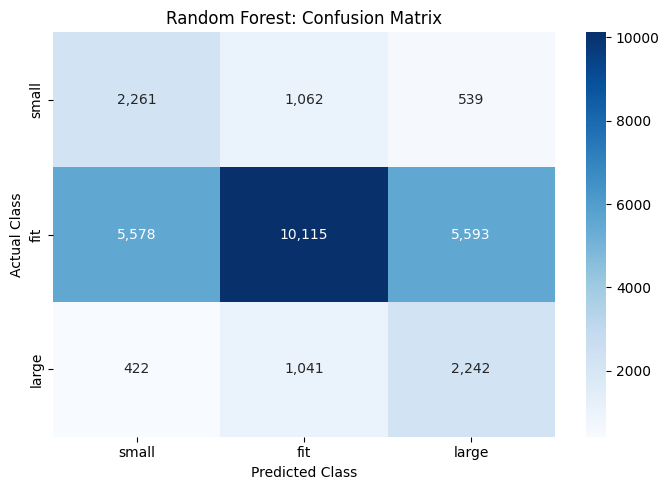

In [33]:
from sklearn.ensemble import RandomForestClassifier

random_forest = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(refined_preprocessor)
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=None,
                min_samples_leaf=2,
                max_features="sqrt",
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        )
    ]
)

start_time = time.time()

random_forest.fit(
    X_train_refined,
    y_train_refined
)

random_forest_time = time.time() - start_time

print(
    f"Training time: {random_forest_time:.2f} seconds"
)

random_forest_metrics, random_forest_predictions = evaluate_model(
    "Random Forest",
    random_forest,
    X_val_refined,
    y_val_refined
)

In [34]:
all_model_results = pd.DataFrame(
    [
        dummy_metrics,
        standard_lr_metrics,
        balanced_lr_metrics,
        refined_lr_metrics,
        random_forest_metrics
    ]
)

all_model_results = all_model_results.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

all_model_results.round(4)

,Model,Accuracy,Balanced Accuracy,Macro F1
0,Refined Class-Weighted Logistic Regression,0.5257,0.6061,0.4795
1,Random Forest,0.5066,0.5553,0.4493
2,Class-Weighted Logistic Regression,0.3590,0.4689,0.3372
3,Standard Logistic Regression,0.7362,0.3348,0.2879
4,Majority-Class Baseline,0.7377,0.3333,0.2830


In [35]:
all_business_results = pd.DataFrame(
    [
        calculate_business_metrics(
            "Majority-Class Baseline",
            y_val,
            dummy_predictions
        ),
        calculate_business_metrics(
            "Standard Logistic Regression",
            y_val,
            standard_lr_predictions
        ),
        calculate_business_metrics(
            "Class-Weighted Logistic Regression",
            y_val,
            balanced_lr_predictions
        ),
        calculate_business_metrics(
            "Refined Class-Weighted Logistic Regression",
            y_val_refined,
            refined_lr_predictions
        ),
        calculate_business_metrics(
            "Random Forest",
            y_val_refined,
            random_forest_predictions
        )
    ]
)

all_business_results.round(4)

,Model,Misfit Recall,Misfit Precision,False Alert Rate
0,Majority-Class Baseline,0.0000,0.0000,0.0000
1,Standard Logistic Regression,0.0062,0.3884,0.0035
2,Class-Weighted Logistic Regression,0.8020,0.2858,0.7124
3,Refined Class-Weighted Logistic Regression,0.7506,0.3364,0.5263
4,Random Forest,0.7221,0.3285,0.5248


### Validation Interpretation

The random forest did not outperform the refined class-weighted logistic regression. Although the random forest captured non-linear interactions, the refined logistic model achieved higher balanced accuracy, macro F1-score and misfit recall.

This suggests that the sparse one-hot encoded representation, including thousands of product indicators, was better handled by the regularised linear classifier than by the random forest configuration. Increasing model complexity therefore did not automatically improve validation performance.

However, both refined models produced false alert rates above 50%. This would create an excessive number of warnings for customers whose selected items would fit correctly. Further refinement therefore focuses on adjusting class weights to achieve a better balance between detecting misfits and avoiding unnecessary alerts.

## 8. Business-Oriented Class Weight Refinement

The automatically balanced class weights substantially improved minority-class recall, but they also produced a high false alert rate. In practice, excessive warnings could frustrate customers and reduce confidence in the system.

Two moderate class-weight configurations are evaluated on the validation set. These settings continue to prioritise `small` and `large` observations while reducing the penalty difference between fit and misfit classes. Macro F1 is used as the primary model-selection metric, while misfit recall and false alert rate are examined as business-oriented trade-offs.

In [36]:
weight_candidates = {
    "Moderate Weight 2": {
        "fit": 1,
        "small": 2,
        "large": 2
    },
    "Moderate Weight 3": {
        "fit": 1,
        "small": 3,
        "large": 3
    }
}

tuned_models = {}
tuned_predictions = {}
tuning_records = []

for model_name, class_weights in weight_candidates.items():

    candidate_model = Pipeline(
        steps=[
            (
                "preprocessor",
                clone(refined_preprocessor)
            ),
            (
                "classifier",
                LogisticRegression(
                    max_iter=500,
                    solver="lbfgs",
                    class_weight=class_weights,
                    random_state=RANDOM_STATE
                )
            )
        ]
    )

    start_time = time.time()

    candidate_model.fit(
        X_train_refined,
        y_train_refined
    )

    training_time = time.time() - start_time

    candidate_predictions = candidate_model.predict(
        X_val_refined
    )

    model_accuracy = accuracy_score(
        y_val_refined,
        candidate_predictions
    )

    model_balanced_accuracy = balanced_accuracy_score(
        y_val_refined,
        candidate_predictions
    )

    model_macro_f1 = f1_score(
        y_val_refined,
        candidate_predictions,
        average="macro"
    )

    business_metrics = calculate_business_metrics(
        model_name,
        y_val_refined,
        candidate_predictions
    )

    tuning_records.append({
        "Model": model_name,
        "Accuracy": model_accuracy,
        "Balanced Accuracy": model_balanced_accuracy,
        "Macro F1": model_macro_f1,
        "Misfit Recall": business_metrics["Misfit Recall"],
        "Misfit Precision": business_metrics["Misfit Precision"],
        "False Alert Rate": business_metrics["False Alert Rate"],
        "Training Time": training_time
    })

    tuned_models[model_name] = candidate_model
    tuned_predictions[model_name] = candidate_predictions

In [37]:
balanced_business_metrics = calculate_business_metrics(
    "Automatically Balanced",
    y_val_refined,
    refined_lr_predictions
)

tuning_records.append({
    "Model": "Automatically Balanced",
    "Accuracy": refined_lr_metrics["Accuracy"],
    "Balanced Accuracy": refined_lr_metrics["Balanced Accuracy"],
    "Macro F1": refined_lr_metrics["Macro F1"],
    "Misfit Recall": balanced_business_metrics["Misfit Recall"],
    "Misfit Precision": balanced_business_metrics["Misfit Precision"],
    "False Alert Rate": balanced_business_metrics["False Alert Rate"],
    "Training Time": refined_lr_time
})

weight_tuning_results = pd.DataFrame(
    tuning_records
)

weight_tuning_results = weight_tuning_results.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

weight_tuning_results.round(4)

,Model,Accuracy,Balanced Accuracy,Macro F1,Misfit Recall,Misfit Precision,False Alert Rate,Training Time
0,Moderate Weight 3,0.6812,0.5789,0.5546,0.5306,0.4278,0.2523,48.2018
1,Moderate Weight 2,0.7323,0.5272,0.5484,0.3754,0.4982,0.1345,43.1150
2,Automatically Balanced,0.5257,0.6061,0.4795,0.7506,0.3364,0.5263,43.3710


### Final Model Selection

The `Moderate Weight 3` configuration was selected because it achieved the highest validation macro F1-score of 0.5538. Compared with the automatically balanced model, it increased accuracy from 0.5259 to 0.6808 and reduced the false alert rate from 0.5261 to 0.2523.

Although `Moderate Weight 2` produced fewer false alerts, it identified only 37.47% of actual misfits. The selected configuration identified 52.94% of misfits while maintaining a substantially lower false alert rate than the automatically balanced model. It therefore provided the most appropriate validation trade-off for the proposed warning system.

## 9. Final Model Evaluation

After model selection, the training and validation sets are combined to provide more observations for final model fitting. The selected class weights are fixed at `fit: 1`, `small: 3` and `large: 3`.

The test set has not been used during feature refinement, model comparison or class-weight selection. It is used once to estimate the final system's generalisation performance.

In [38]:
X_final_train = pd.concat(
    [
        X_train_refined,
        X_val_refined
    ],
    axis=0
)

y_final_train = pd.concat(
    [
        y_train_refined,
        y_val_refined
    ],
    axis=0
)

print(
    "Final training data:",
    X_final_train.shape
)

print(
    "Untouched test data:",
    X_test_refined.shape
)

Final training data: (163501, 9)
Untouched test data: (28854, 9)


In [39]:
final_model = Pipeline(
    steps=[
        (
            "preprocessor",
            clone(refined_preprocessor)
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=500,
                solver="lbfgs",
                class_weight={
                    "fit": 1,
                    "small": 3,
                    "large": 3
                },
                random_state=RANDOM_STATE
            )
        )
    ]
)

start_time = time.time()

final_model.fit(
    X_final_train,
    y_final_train
)

final_training_time = time.time() - start_time

print(
    f"Final training time: "
    f"{final_training_time:.2f} seconds"
)

Final training time: 55.21 seconds


Final Business-Tuned Logistic Regression
Accuracy: 0.6770
Balanced accuracy: 0.5728
Macro F1-score: 0.5493

Classification report:


,precision,recall,f1-score,support
small,0.387,0.480,0.428,3862.000
fit,0.813,0.745,0.778,21287.000
large,0.400,0.494,0.442,3705.000
accuracy,0.677,0.677,0.677,0.677
macro avg,0.533,0.573,0.549,28854.000
weighted avg,0.703,0.677,0.688,28854.000


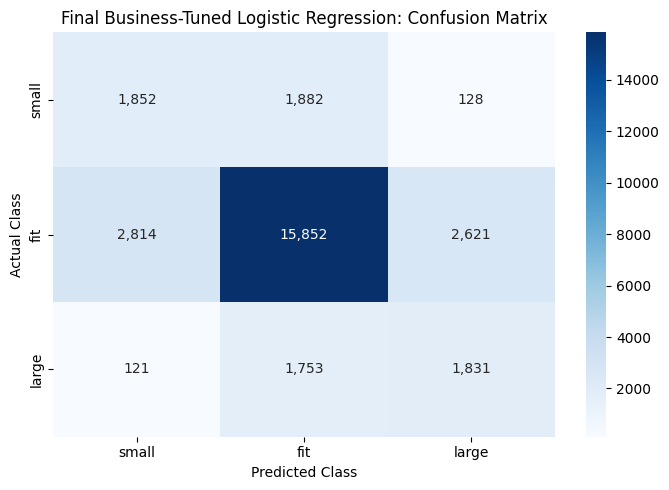

In [40]:
final_test_metrics, final_test_predictions = evaluate_model(
    "Final Business-Tuned Logistic Regression",
    final_model,
    X_test_refined,
    y_test_refined
)

In [41]:
final_test_business_metrics = calculate_business_metrics(
    "Final Business-Tuned Logistic Regression",
    y_test_refined,
    final_test_predictions
)

pd.DataFrame(
    [final_test_business_metrics]
).round(4)

,Model,Misfit Recall,Misfit Precision,False Alert Rate
0,Final Business-Tuned Logistic Regression,0.5196,0.4198,0.2553


In [42]:
selected_validation_result = (
    weight_tuning_results[
        weight_tuning_results["Model"]
        == "Moderate Weight 3"
    ].iloc[0]
)

validation_test_comparison = pd.DataFrame(
    [
        {
            "Dataset": "Validation",
            "Accuracy": selected_validation_result["Accuracy"],
            "Balanced Accuracy": selected_validation_result[
                "Balanced Accuracy"
            ],
            "Macro F1": selected_validation_result["Macro F1"],
            "Misfit Recall": selected_validation_result["Misfit Recall"],
            "Misfit Precision": selected_validation_result[
                "Misfit Precision"
            ],
            "False Alert Rate": selected_validation_result[
                "False Alert Rate"
            ]
        },
        {
            "Dataset": "Test",
            "Accuracy": final_test_metrics["Accuracy"],
            "Balanced Accuracy": final_test_metrics[
                "Balanced Accuracy"
            ],
            "Macro F1": final_test_metrics["Macro F1"],
            "Misfit Recall": final_test_business_metrics[
                "Misfit Recall"
            ],
            "Misfit Precision": final_test_business_metrics[
                "Misfit Precision"
            ],
            "False Alert Rate": final_test_business_metrics[
                "False Alert Rate"
            ]
        }
    ]
)

validation_test_comparison.round(4)

,Dataset,Accuracy,Balanced Accuracy,Macro F1,Misfit Recall,Misfit Precision,False Alert Rate
0,Validation,0.6812,0.5789,0.5546,0.5306,0.4278,0.2523
1,Test,0.6770,0.5728,0.5493,0.5196,0.4198,0.2553


## 10. Model Structure, Loss Function and Training Algorithm

### Multinomial Logistic Regression

The final model is a multinomial logistic regression classifier. For each possible fit class \(k\), the model first calculates a linear score:

$$
z_k = \mathbf{w}_k^\top \mathbf{x} + b_k
$$

where $\mathbf{x}$ is the preprocessed input vector, $\mathbf{w}_k$ contains the learned coefficients for class $k$, and $b_k$ is the intercept.

The scores are converted into class probabilities using the softmax function:

$$
P(y=k \mid \mathbf{x}) =
\frac{\exp(z_k)}
{\sum_{j=1}^{K}\exp(z_j)}
$$

The predicted output is the class with the highest estimated probability:

$$
\hat{y} = \arg\max_k P(y=k \mid \mathbf{x})
$$

### Weighted Cross-Entropy Loss

The model is trained using class-weighted cross-entropy loss:

$$
L =
-\frac{1}{N}
\sum_{i=1}^{N}
\alpha_{y_i}
\log P(y_i \mid \mathbf{x}_i)
+
\frac{\lambda}{2}\|\mathbf{W}\|_2^2
$$

The selected class weights are:

- `fit`: 1
- `small`: 3
- `large`: 3

Therefore, incorrectly classifying a `small` or `large` observation contributes three times as much to the training loss as incorrectly classifying a `fit` observation. This encourages the model to identify more potentially unsuitable rentals.

L2 regularisation is included to limit excessively large coefficients, particularly because one-hot encoding creates thousands of input variables. Scikit-learn controls regularisation using `C`, where a smaller value represents stronger regularisation. The default value `C=1.0` is used.

### Optimisation

The `lbfgs` solver minimises the regularised weighted cross-entropy loss. L-BFGS is a quasi-Newton optimisation method that uses gradient information and an approximation of curvature to update the model coefficients. A maximum of 500 iterations is allowed.

The full implementation combines preprocessing and classification in a scikit-learn `Pipeline`. This ensures that missing-value imputation, standardisation and one-hot encoding are learned from the training data and then applied consistently to new inputs.

## 11. Model Interpretation

The fitted model coefficients are examined to understand which general customer and garment characteristics are most strongly associated with each predicted fit category.

In [43]:
fitted_preprocessor = final_model.named_steps[
    "preprocessor"
]

fitted_classifier = final_model.named_steps[
    "classifier"
]

feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

clean_feature_names = [
    name.replace("numeric__", "")
        .replace("categorical__", "")
    for name in feature_names
]

coefficient_table = pd.DataFrame(
    fitted_classifier.coef_.T,
    index=clean_feature_names,
    columns=fitted_classifier.classes_
)

print(
    "Number of transformed features:",
    coefficient_table.shape[0]
)

print(
    "Model classes:",
    fitted_classifier.classes_
)

Number of transformed features: 5986
Model classes: ['fit' 'large' 'small']


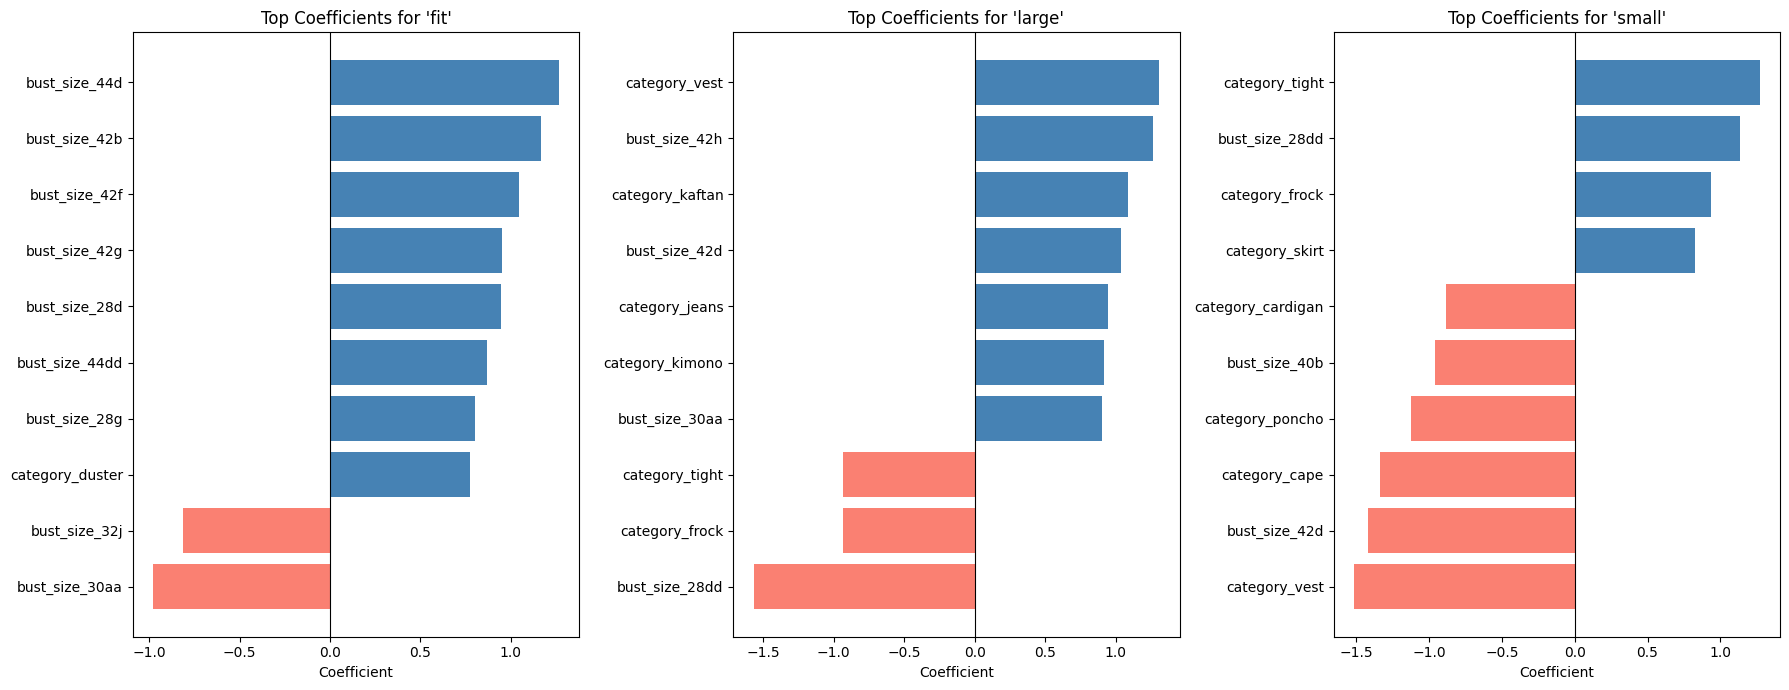

In [44]:
general_coefficient_table = coefficient_table[
    ~coefficient_table.index.str.startswith(
        "item_id_"
    )
].copy()

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 7)
)

for ax, class_name in zip(
    axes,
    fitted_classifier.classes_
):
    class_coefficients = (
        general_coefficient_table[class_name]
    )

    top_features = (
        class_coefficients
        .abs()
        .sort_values(ascending=False)
        .head(10)
        .index
    )

    plotted_values = (
        class_coefficients
        .loc[top_features]
        .sort_values()
    )

    colors = [
        "steelblue" if value > 0
        else "salmon"
        for value in plotted_values
    ]

    ax.barh(
        plotted_values.index,
        plotted_values.values,
        color=colors
    )

    ax.axvline(
        0,
        color="black",
        linewidth=0.8
    )

    ax.set_title(
        f"Top Coefficients for '{class_name}'"
    )

    ax.set_xlabel("Coefficient")

plt.tight_layout()
plt.show()

### Coefficient Interpretation

A positive coefficient increases the score assigned to the corresponding class, while a negative coefficient decreases it, holding the other transformed inputs constant. The coefficients indicate associations learned by the model and should not be interpreted as causal effects.

Product identifiers are excluded from this visualisation because there are thousands of individual items. Their inclusion in training remains important for capturing product-specific fit tendencies.

Some of the largest coefficients correspond to infrequent categorical levels, such as uncommon bust-size values. These coefficients may be less stable than those based on frequently observed categories. Therefore, the chart is used as a descriptive interpretation of the fitted model rather than a definitive feature-importance ranking.


## 12. Deployment Example

The following example demonstrates how the final pipeline processes one new rental decision and returns both a predicted fit category and the corresponding class probabilities.

In [45]:
example_input = X_test_refined.iloc[
    [0]
].copy()

example_prediction = final_model.predict(
    example_input
)[0]

example_probabilities = pd.DataFrame(
    final_model.predict_proba(
        example_input
    ),
    columns=fitted_classifier.classes_
)

print("Example deployment input:")
display(example_input)

print(
    "Predicted fit category:",
    example_prediction
)

print("Predicted class probabilities:")
display(
    example_probabilities.round(4)
)

Example deployment input:


,bust_size,rented_for,body_type,category,size,age,weight_lbs,height_inches,item_id
86698,NaN,wedding,hourglass,dress,32,26.0,205.0,66.0,124553


Predicted fit category: large
Predicted class probabilities:


,fit,large,small
0,0.3839,0.3997,0.2164


The deployment output contains three estimated probabilities and one final predicted class. In a practical system, a predicted result of `small` or `large` would trigger a size-review warning before the rental is confirmed.

## 13. Discussion and Limitations

The final business-tuned logistic regression achieved a test accuracy of 0.6770, balanced accuracy of 0.5728 and macro F1-score of 0.5493. The close validation and test results suggest that the selected model generalised consistently to the held-out test data.

Raw accuracy alone gives a misleading impression in this task. The majority-class baseline achieved higher accuracy by predicting nearly every observation as `fit`, but it identified none of the unsuitable rentals. The final model identified 51.96% of actual misfits and reduced the false alert rate to 25.53%. This represents a more useful trade-off for a pre-rental warning system, although the result is not strong enough for fully automated deployment.

The model has several limitations. First, product identity is important to its performance, so the evaluation mainly represents garments already observed in the historical catalogue. Predictions for completely new items are less reliable. Second, the dataset contains missing customer measurements and self-reported fit labels, which may introduce noise. Third, the available variables do not describe garment material, cut, brand or detailed dimensions. Finally, the selected class weights are based on validation performance rather than observed financial costs.

Future work could incorporate detailed garment measurements, brand information and fabric properties. Product or customer embeddings could also represent similarities more effectively than one-hot encoded identifiers. A temporal or new-item evaluation would provide stronger evidence about performance under catalogue changes. If real return costs and customer responses were available, the class weights or alert threshold could be optimised using an explicit business-cost function.

## 14. Conclusion

This project developed a pre-rental clothing fit warning system using the RentTheRunway dataset. Initial models based only on general customer and garment attributes performed poorly on the minority fit classes. Adding product identity substantially improved balanced performance, while a random forest did not outperform the refined logistic regression.

Class-weight refinement produced a more practical balance between identifying unsuitable rentals and avoiding unnecessary warnings. The final model achieved a test macro F1-score of 0.5493 and detected 51.96% of misfits with a 25.53% false alert rate. The results show that machine learning can provide useful fit-risk information, but further data and model development would be necessary before real-world deployment.

## 15. References

Misra, R., Wan, M., & McAuley, J. (2018). Decomposing fit semantics for product size recommendation in metric spaces. *Proceedings of the 12th ACM Conference on Recommender Systems*, 422–426. https://doi.org/10.1145/3240323.3240398

McAuley Lab. (n.d.). *Recommender systems datasets: Clothing fit data*. https://cseweb.ucsd.edu/~jmcauley/datasets.html